# 01b — Qué hay en cada dataset y por qué cada uno lleva su modelo

Este notebook muestra ejemplos reales de los tres datasets que usamos y, mirando las fotos, explica por qué en cada
uno usamos el modelo que usamos y por qué no se puede usar el mismo en los otros.

| Dataset | Qué es | Modelo que usamos |
|---|---|---|
| **CISUTAC** Holes / Spots | Fotos de prendas usadas completas, con cajas de agujeros o manchas | **YOLO11n** (detección supervisada) |
| **RAW-FABRID** | Tela cruda de fábrica, cámara industrial, con muchísima tela sana | **PatchCore** (detección de anomalías) |
| **FabriD v3** | Primeros planos de tela RGB, con polígonos de defectos **y** telas sanas | **Los dos**: YOLO11n-seg vs. PatchCore |

Recordatorio de la diferencia entre los dos paradigmas:

- **Supervisado (YOLO):** aprende de ejemplos de defectos marcados. Necesita **etiquetas de defectos**.
- **Anomalías (PatchCore):** aprende sólo cómo es la tela **sana** y marca lo que se aparta de eso. Necesita **muchas
  imágenes sanas y parecidas entre sí**, pero ninguna etiqueta de defecto.

Cada dataset cumple los requisitos de uno de los dos paradigmas, y sólo FabriD cumple los de ambos.

**Datos:** CISUTAC se lee de la carpeta de datos (`REWEAR_DATA_DIR`), preparada con `scripts/prepare_cisutac_yolo.py`.
RAW-FABRID (4 GB) y FabriD (13 GB) no hacen falta: se muestran las figuras que el EDA generó a partir de sus
archivos originales, guardadas en `reports/`. Sólo se miran ejemplos de **train**; el test no se usa.

In [1]:
import os, random, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as Figura, display
from matplotlib.patches import Rectangle
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if "REWEAR_DATA_DIR" not in os.environ and not (ROOT / "data").exists():
    os.environ["REWEAR_DATA_DIR"] = str(Path.home() / "rewear_data")   # ubicación usada en la compu de Pepo
sys.path.insert(0, str(ROOT / "src"))
import cisutac_baseline as cb

REPORTS = ROOT / "reports"
plt.rcParams["figure.dpi"] = 80
%config InlineBackend.figure_formats = ["jpeg"]   # JPEG para que el notebook no pese decenas de MB


def mostrar_figura(ruta, ancho=1100):
    # Muestra una figura guardada del EDA, reducida y en JPEG.
    import io
    with Image.open(ruta) as fig:
        fig = fig.convert("RGB")
        fig.thumbnail((ancho, 10 * ancho))
        buffer = io.BytesIO()
        fig.save(buffer, format="JPEG", quality=85)
    display(Figura(data=buffer.getvalue(), format="jpeg"))
SEMILLA = 2026
print("Datos CISUTAC:", cb.DATA)

Datos CISUTAC: C:\Users\pepob\rewear_data


## 1. CISUTAC: prendas usadas reales

Fotos de prendas posconsumo (camperas, pantalones, remeras) colgadas en una percha, con el fondo difuminado, de
**2160×3840 px**. Son dos datasets separados, cada uno con **una sola clase**: `Hole` (agujero) o `Spot` (mancha).
Las anotaciones son **cajas**. Usamos sólo las fotos originales (las copias de 640×640 de Roboflow son la misma foto)
con el split propio agrupado por día de captura.

In [2]:
filas = []
for ds in ("holes", "spots"):
    for split in ("train", "valid", "test"):
        g = cb.load_ground_truth(ds, split)
        con_defecto = {a["image_id"] for a in g["annotations"]}
        filas.append({"dataset": ds, "split": split, "fotos": len(g["images"]), "defectos": len(g["annotations"]),
                      "fotos SIN defectos (sanas)": len(g["images"]) - len(con_defecto),
                      "defectos chicos (< 32 px)": sum(a["area"] ** 0.5 < 32 for a in g["annotations"])})
pd.DataFrame(filas).set_index(["dataset", "split"])

fotos  defectos  fotos SIN defectos (sanas)  \
dataset split                                                
holes   train    300       589                           0   
        valid     43        71                           0   
        test      64       125                           0   
spots   train    361      1903                           0   
        valid     59       284                           0   
        test      66       311                           0   

               defectos chicos (< 32 px)  
dataset split                             
holes   train                        348  
        valid                         35  
        test                          74  
spots   train                       1262  
        valid                        199  
        test                         207

Dos datos de la tabla deciden todo lo que sigue:

- **Cero fotos sanas.** Todas las prendas tienen algún defecto anotado.
- **La mayoría de los defectos son chicos**, aun medidos en la foto original de 2160×3840.

### Cómo se ve una foto completa

Fotos al azar de train. La caja roja es el defecto anotado; los defectos de menos de 32 px, que a esta escala no se
ven, se marcan además con un círculo amarillo.

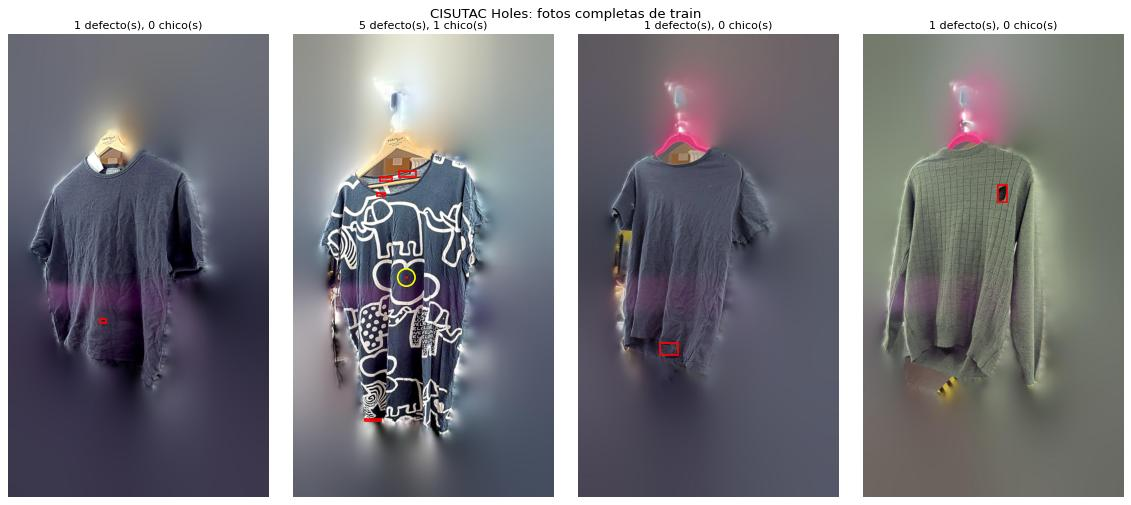

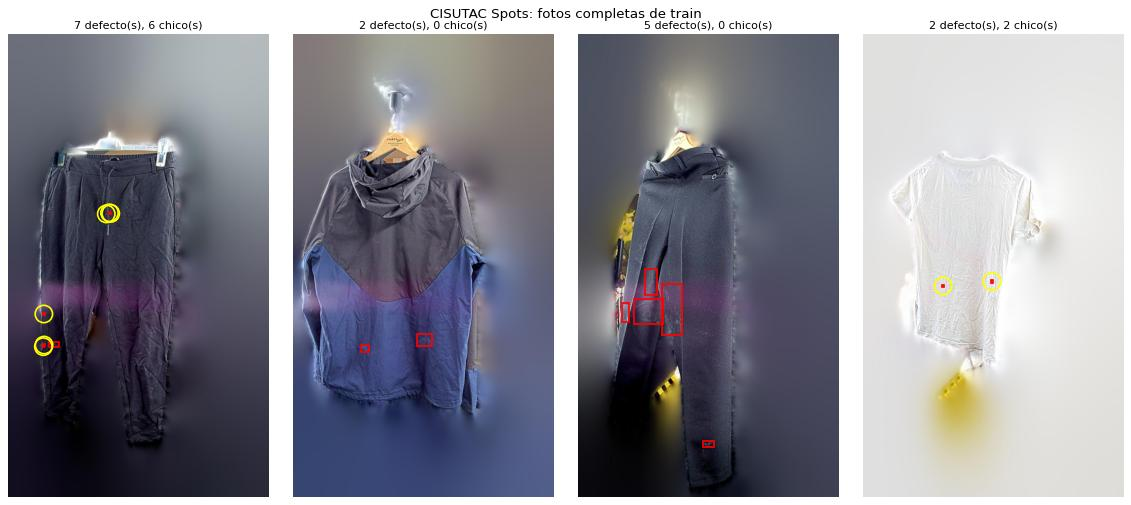

In [3]:
def mostrar_fotos(ds, n=4, split="train", seed=SEMILLA):
    g = cb.load_ground_truth(ds, split)
    por_imagen = {}
    for a in g["annotations"]:
        por_imagen.setdefault(a["image_id"], []).append(a)
    elegidas = random.Random(seed).sample(g["images"], n)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 6.4))
    for ax, im in zip(axes, elegidas):
        with Image.open(cb.original_dir(ds) / im["file_name"]) as foto:
            escala = 540 / foto.width
            ax.imshow(foto.convert("RGB").resize((540, round(foto.height * escala))))
        cajas = por_imagen.get(im["id"], [])
        for a in cajas:
            x, y, w, h = (v * escala for v in a["bbox"])
            ax.add_patch(Rectangle((x, y), w, h, fill=False, ec="red", lw=1.5))
            if a["area"] ** 0.5 < 32:
                ax.add_patch(plt.Circle((x + w / 2, y + h / 2), 18, fill=False, ec="yellow", lw=1.5))
        chicos = sum(a["area"] ** 0.5 < 32 for a in cajas)
        ax.set_title(f"{len(cajas)} defecto(s), {chicos} chico(s)", fontsize=10)
        ax.axis("off")
    fig.suptitle(f"CISUTAC {ds.capitalize()}: fotos completas de train", fontsize=12)
    plt.tight_layout()
    plt.show()

mostrar_fotos("holes")
mostrar_fotos("spots")

**Qué se ve:**

- Cada foto es **una prenda distinta**: otro tipo de prenda, otro color, otra tela, estampados, logos, arrugas, la
  percha y el borde difuminado. No hay "una tela" que se repita.
- A esta escala **los defectos chicos no se ven**: sin el círculo amarillo no sabríamos dónde están.

### El mismo defecto a resolución original y con la foto achicada

Arriba, el recorte a resolución original. Abajo, el mismo lugar después de achicar la foto entera a 640 o 1280 px de
lado mayor (lo que hace YOLO por defecto), ampliado para mostrarlo al mismo tamaño. El defecto está siempre en el
centro del recorte, y el título dice cuántos píxeles de lado le quedan.

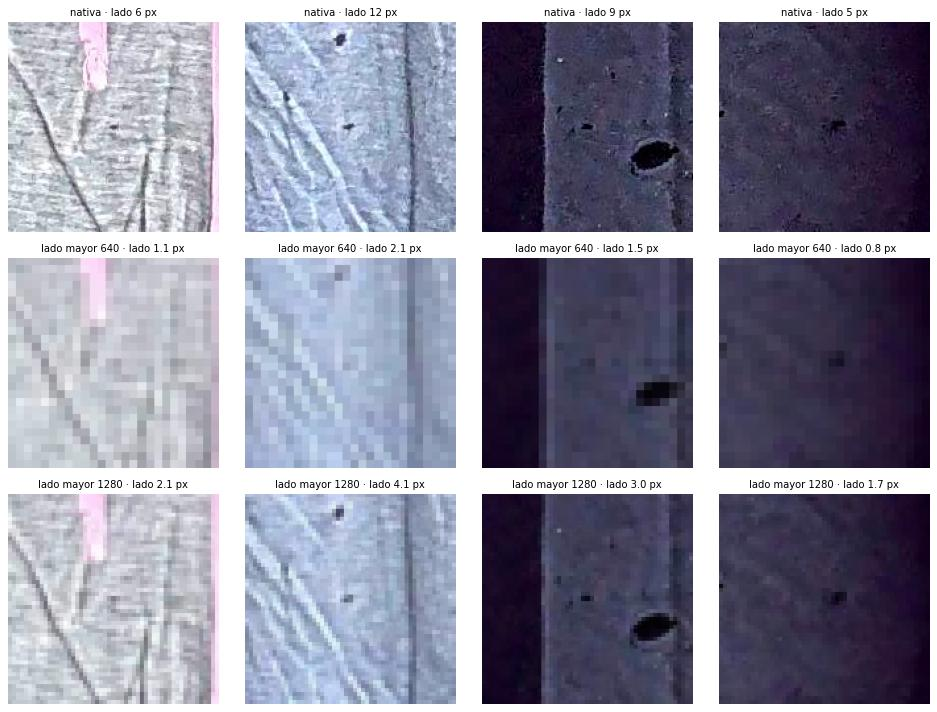

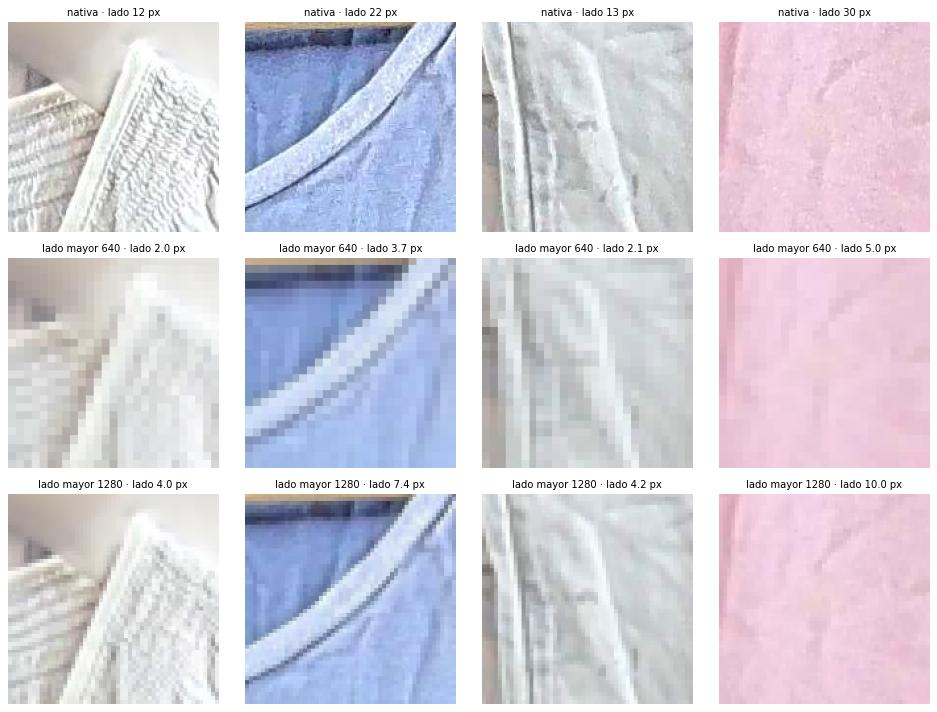

In [4]:
cb.plot_resolution_zoom("holes", split="train", sides=(640, 1280), n=4, seed=SEMILLA)
plt.show()
cb.plot_resolution_zoom("spots", split="train", sides=(640, 1280), n=4, seed=SEMILLA)
plt.show()

A 640 el defecto queda en 3–4 píxeles borrosos, menos que una celda de la grilla más fina de YOLO (8×8 px). Por eso
la contribución del TP es procesar la foto por **tiles de 640 a resolución original** (variante A3): en el test de
Spots, la foto entera a 640 encuentra 1 de 207 manchas chicas y A3 encuentra 39.

### ¿Qué sería "lo normal" en CISUTAC?

Una foto por prenda, todas de train:

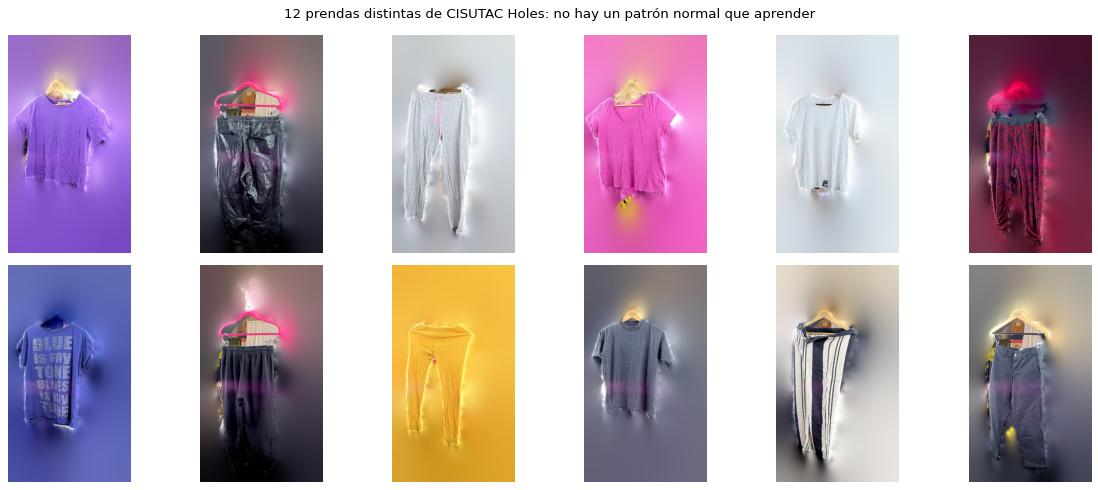

In [5]:
g = cb.load_ground_truth("holes", "train")
muestra = random.Random(SEMILLA + 1).sample(g["images"], 12)
fig, axes = plt.subplots(2, 6, figsize=(15, 6.2))
for ax, im in zip(axes.flat, muestra):
    with Image.open(cb.original_dir("holes") / im["file_name"]) as foto:
        foto.thumbnail((240, 420))
        ax.imshow(foto.convert("RGB"))
    ax.axis("off")
fig.suptitle("12 prendas distintas de CISUTAC Holes: no hay un patrón normal que aprender", fontsize=12)
plt.tight_layout()
plt.show()

### Por qué en CISUTAC usamos YOLO y no PatchCore

1. **Tiene lo que YOLO necesita:** cientos de defectos anotados con cajas (589 agujeros y 1.903 manchas en train).
2. **No tiene lo que PatchCore necesita:** PatchCore se entrena **sólo con ejemplos sanos**, y CISUTAC tiene **cero
   prendas sanas**. No hay con qué armar el banco de memoria.
3. **Aunque consiguiéramos prendas sanas, "lo normal" sería demasiado amplio.** Como se ve en la grilla, cada prenda
   tiene otra tela, otro color, estampados, logos y costuras. PatchCore marcaría como anómalo cualquier estampado que
   no haya visto, no sólo los agujeros. Esto se confirmó en FabriD (sección 3), donde las telas varían mucho menos y
   PatchCore ya cae.
4. **Escala:** PatchCore trabaja con la imagen reducida a 256×256. Si a 640 los defectos ya desaparecen, a 256 no
   queda nada.
5. **Tampoco se podría evaluar bien:** sin prendas sanas no se puede medir cuántas veces el detector de anomalías
   marca defecto en una prenda que no tiene ninguno.

## 2. RAW-FABRID: tela cruda industrial

Fotos de tela cruda tomadas en fábrica con una cámara *line-scan*, de **1792×1024 px**, monocromáticas, de 7 rollos.
Viene cortado en **parches de 256×256** con el formato MVTec, el estándar de detección de anomalías:

| Conjunto | Parches | De dónde salen |
|---|---:|---|
| `train/good` (entrenamiento) | **14.196** sanos | 507 fotos sanas |
| `test/good` | 4.969 sanos | 202 fotos con defecto |
| `test/defect` | 687 con defecto, **cada uno con su máscara** por píxel | las mismas 202 fotos |

Los defectos son de una sola clase genérica: no distingue agujero, mancha o hilo.

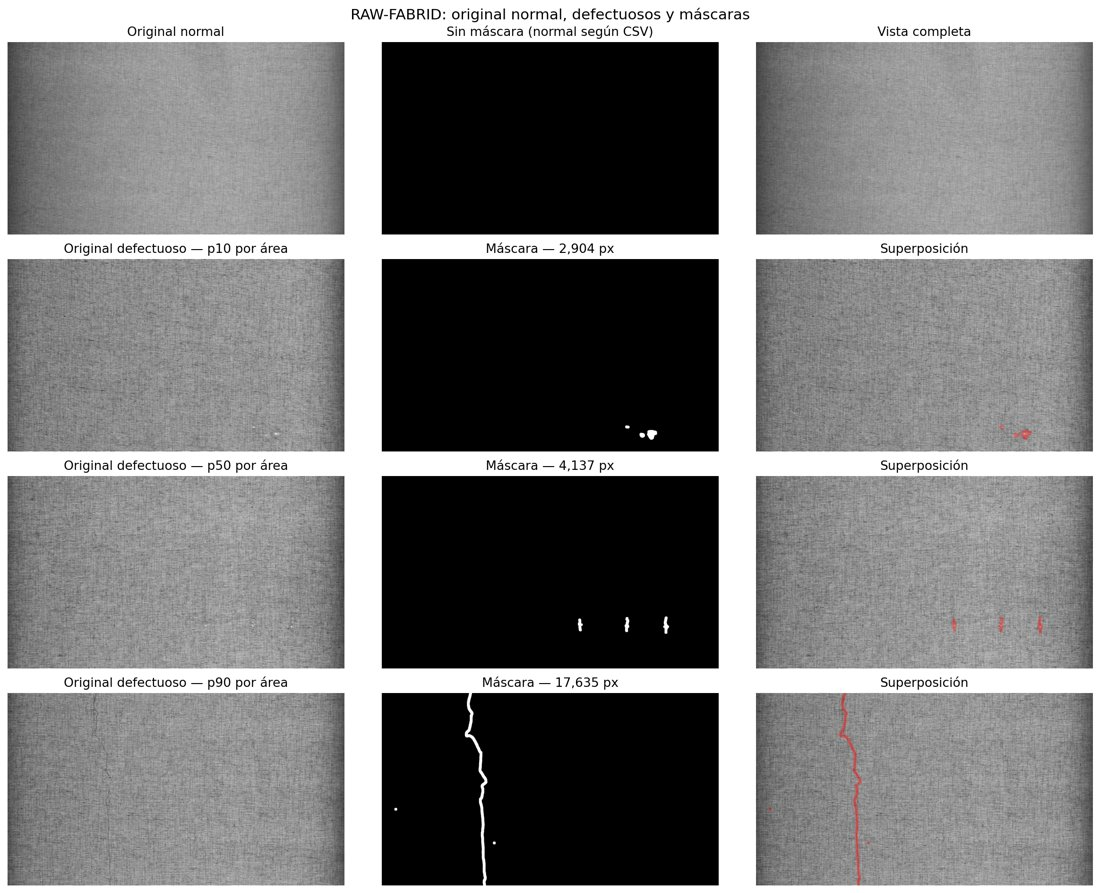

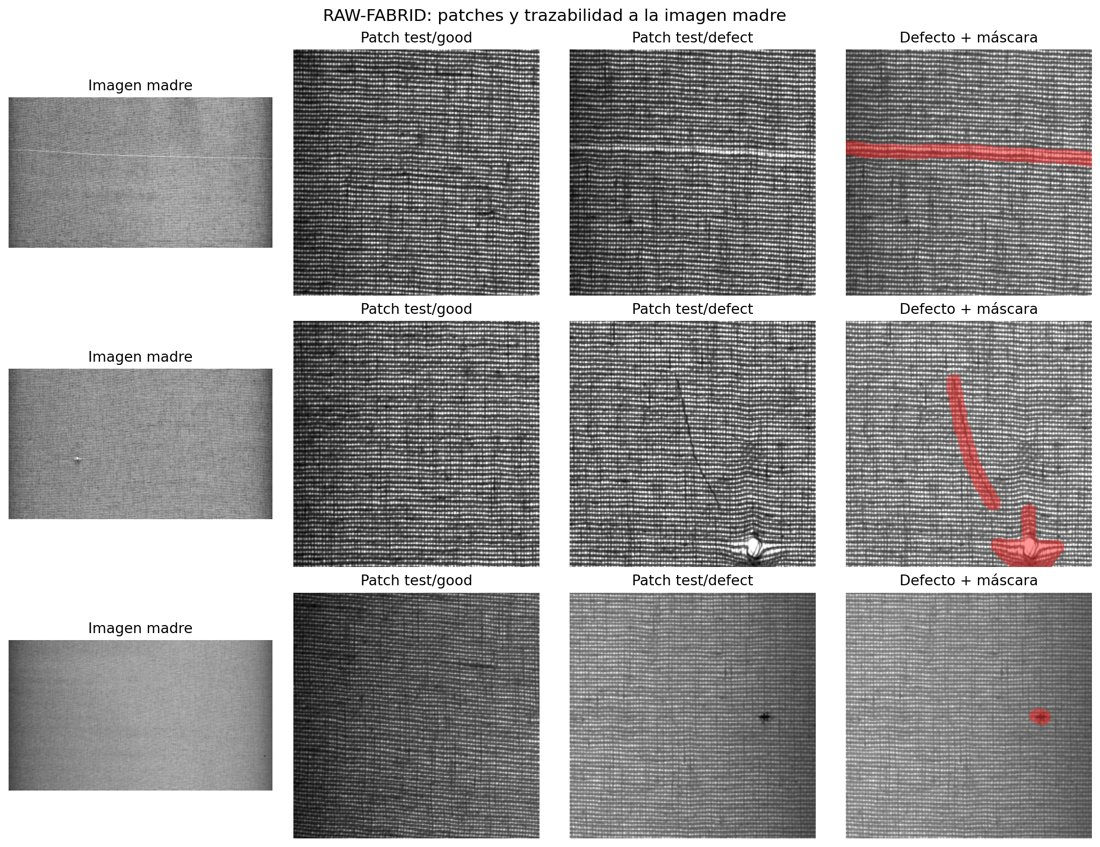

In [6]:
mostrar_figura(REPORTS / "raw_fabrid" / "raw2_originales_mascaras.png")
mostrar_figura(REPORTS / "raw_fabrid" / "raw2_parches.png")

**Qué se ve:** todas las fotos son **la misma tela, con la misma cámara, la misma luz y el mismo encuadre**. Un parche
sano se parece muchísimo a cualquier otro parche sano. El defecto (un hilo cortado, un nudo, un punto) es lo único que
rompe el patrón del tejido.

### Por qué en RAW-FABRID usamos PatchCore y no YOLO

1. **Es el caso ideal de PatchCore:** 14.196 parches sanos y una textura repetitiva y homogénea. "Lo normal" está muy
   bien definido, así que cualquier cosa distinta es un defecto. Resultado en test: **AUROC 0,90** por parche, mejor
   que PaDiM (0,86) y que el método clásico de estadística local (0,60).
2. **Tiene máscaras por píxel**, que permiten medir si el mapa de anomalía de PatchCore **ubica** el defecto (AUROC por
   píxel y AUPRO), no sólo si lo detecta.
3. **No sirve para YOLO tal como viene:** el split oficial pone **todos** los defectos en test y train es sólo tela
   sana. Para entrenar un detector habría que sacar defectos del test, y quedarían muy pocos para evaluar (361
   defectos en total, en 202 fotos).
4. **Una sola clase genérica de defecto:** no se puede emparejar con "agujero" o "mancha" de CISUTAC.
5. **Es otro mundo visual:** gris, line-scan y con la tela plana. Un modelo entrenado acá no se puede aplicar a fotos
   de prendas en una percha.

## 3. FabriD v3: el único donde se pueden comparar los dos paradigmas

Primeros planos de tela RGB tomados con celular o cámara: **2.407 fotos**, 620 declaradas sanas (607 confiables
después del EDA) y cuatro clases de defecto (agujero, mancha, marca de aguja, hilo faltante) anotadas con
**polígonos**. Las resoluciones van de 512×512 a 4160×3120.

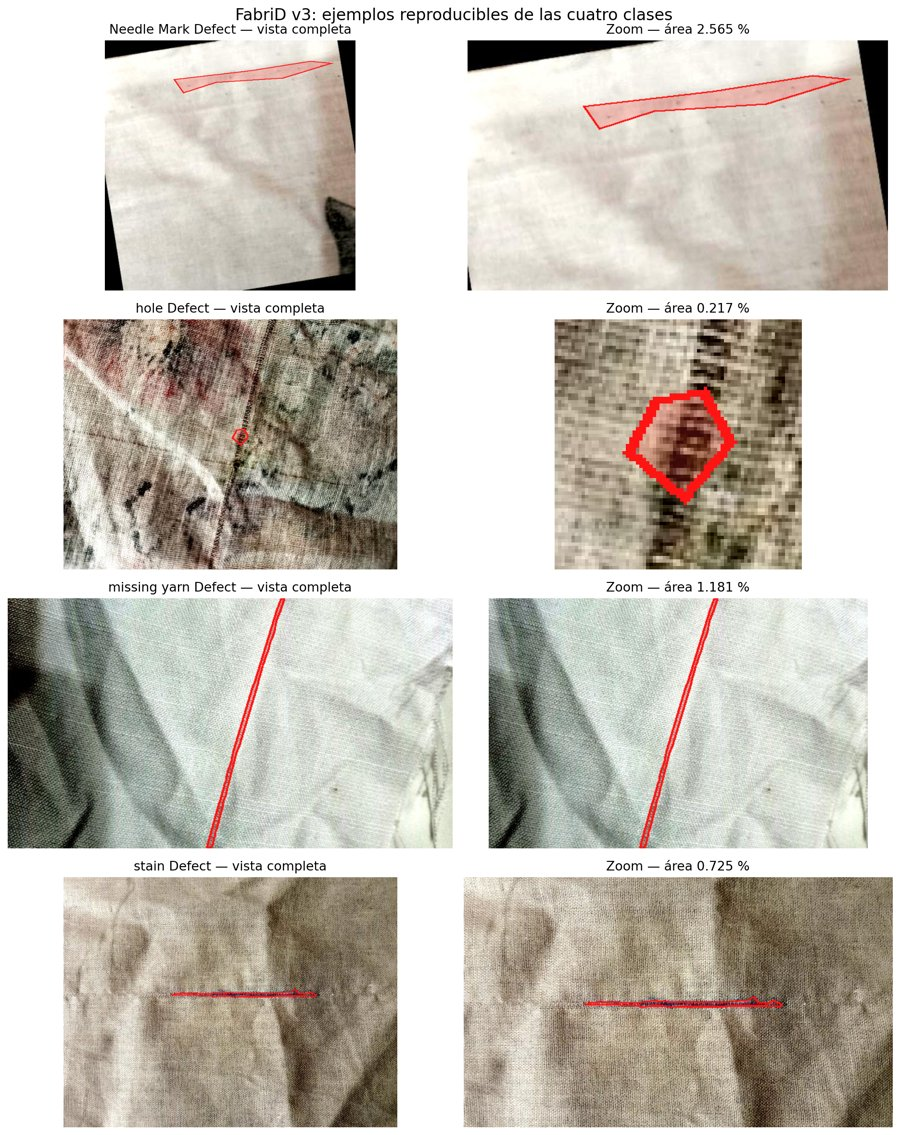

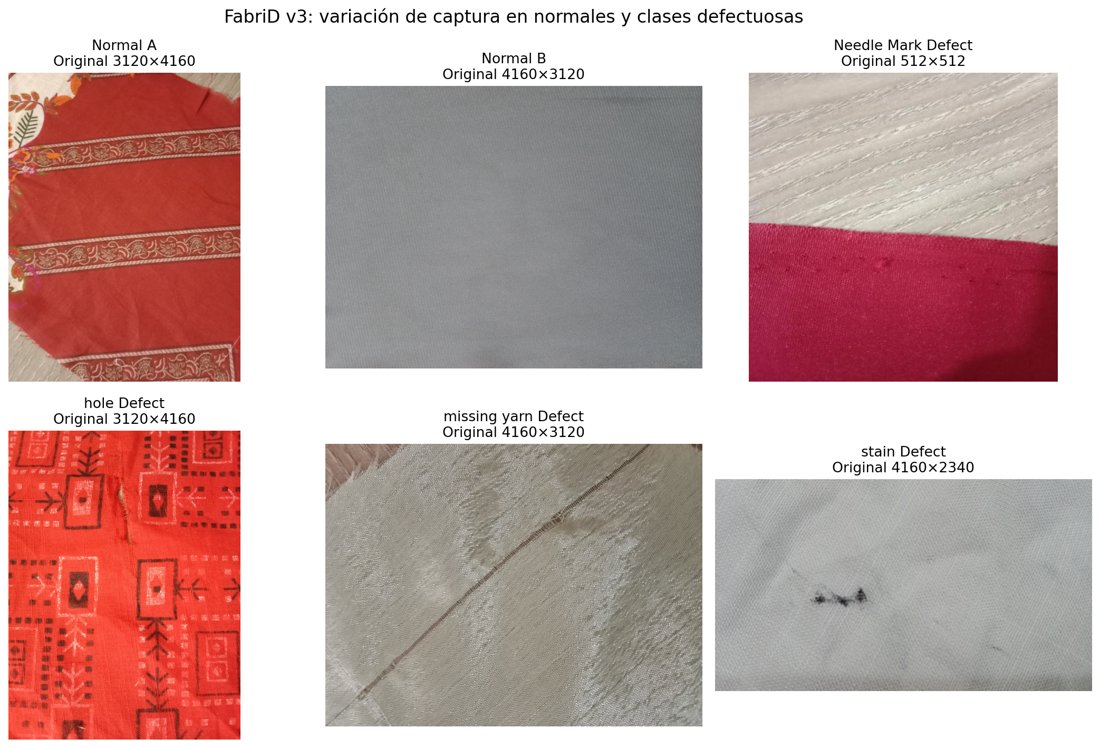

In [7]:
mostrar_figura(REPORTS / "fabrid" / "fab2_clases_poligonos.png", ancho=900)
mostrar_figura(REPORTS / "fabrid" / "fab2_normales_defectos.png")

**Qué se ve:**

- Tiene **las dos cosas**: polígonos de defectos (para YOLO-seg) y telas sanas (para PatchCore). Por eso es el único
  dataset donde los dos modelos se entrenan y se evalúan **sobre las mismas imágenes de test con las mismas
  métricas**.
- Las telas sanas **varían mucho**: tela roja estampada, tela gris lisa, otras texturas, encuadres y luces.
- Hay un **atajo posible**: casi todas las marcas de aguja son fotos de 512×512 y ninguna sana tiene ese tamaño. Un
  modelo podría aprender "foto chica = defecto".

### Qué pasó al comparar en el mismo test

| Modelo | AUROC por imagen (test) | Dice (superposición de la máscara) |
|---|---:|---:|
| **YOLO11n-seg** (supervisado) | **0,87** | **0,56** |
| PatchCore (anomalías) | 0,64 | 0,10 |

La diferencia es de +0,23 a favor del supervisado, con un intervalo de confianza del 95 % de [0,15; 0,31] que no
incluye el cero.

**Por qué PatchCore cae de 0,90 en RAW-FABRID a 0,64 acá:** en RAW-FABRID todas las telas sanas son iguales; en FabriD
"lo normal" incluye estampados, colores y texturas muy distintos, así que una tela sana que no se parece a las del
banco ya parece anómala. El notebook 05 pone a prueba esta hipótesis y otras (tamaño de los defectos, clase, atajo de
captura).

Este resultado también refuerza la decisión de la sección 1: si PatchCore ya sufre con la variedad de FabriD, en
CISUTAC, con prendas completas, estampados, logos y percha, sería todavía peor.

## 4. Los tres dominios, lado a lado

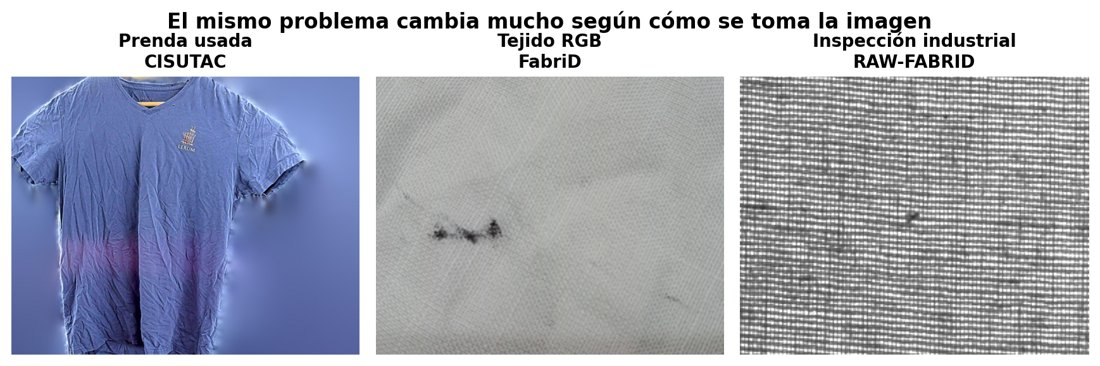

In [8]:
mostrar_figura(REPORTS / "integracion" / "comparacion_dominios.png")

El mismo tipo de defecto se ve completamente distinto según cómo se toma la foto: una prenda entera colgada, un primer
plano de tela o un escaneo industrial. Por eso no mezclamos los datasets ni comparamos cifras entre ellos: cada
pregunta se responde en el dataset que la permite.

## 5. Resumen

| | CISUTAC | RAW-FABRID | FabriD v3 |
|---|---|---|---|
| **Imagen** | Prenda completa en percha, 2160×3840 | Tela industrial gris, parches de 256×256 | Primer plano de tela RGB |
| **Etiquetas** | Cajas (agujero **o** mancha) | Máscaras por píxel (defecto genérico) | Polígonos de 4 clases |
| **Ejemplos sanos** | **Ninguno** | **14.196 parches** | 607 fotos |
| **Variedad de lo normal** | Altísima (cada prenda es distinta) | Mínima (misma tela y cámara) | Alta (telas y capturas distintas) |
| **Modelo** | YOLO11n + tiles | PatchCore | YOLO11n-seg **y** PatchCore |
| **Por qué ese** | Hay defectos etiquetados; el desafío es la escala | Muchos sanos y homogéneos: lo que PatchCore necesita | Es el único con etiquetas y sanos: comparación justa |
| **Por qué no el otro** | Sin sanos no hay PatchCore; y "lo normal" no existe | Todos los defectos están en test; una sola clase genérica | — (se usan los dos) |
| **Pregunta que responde** | ¿Los tiles recuperan los defectos chicos? | ¿Qué tan bien detecta anomalías PatchCore en su caso ideal? | ¿Cuál paradigma es mejor sobre los mismos datos? |